## 1. Imports, settings and text-cleaning function

In [1]:
import json
import os
import pickle
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix, f1_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

LABELS = ["Positive", "Negative", "Neutral", "Irrelevant"]

# Keep negations so "not good" and "good" don't look the same
KEEP = {"no", "not", "nor", "never", "cannot", "nothing"}
STOP_WORDS = set(ENGLISH_STOP_WORDS) - KEEP
URL_RE = re.compile(r"https?://\S+|www\.\S+|pic\.twitter\.com/\S+")
NON_ALNUM_RE = re.compile(r"[^a-z0-9\s]")


def clean_text(text):
    """Lowercase, strip <unk>/URLs/punctuation, drop stop words."""
    text = str(text).lower().replace("<unk>", " ")
    text = URL_RE.sub(" ", text)
    text = NON_ALNUM_RE.sub(" ", text)
    return " ".join(t for t in text.split() if t not in STOP_WORDS)


# Quick self-test: should print "check not like"
print(clean_text("Check this out!! https://t.co/xyz I do NOT like it <unk>"))

check not like


In [2]:
matches = list(Path.cwd().glob("twitter_training - twitter_training.csv")) + list(Path.cwd().parent.glob("twitter_training - twitter_training.csv"))
if not matches:
    raise FileNotFoundError("Put the twitter_training CSV in the same folder as this notebook.")
DATA_PATH = matches[0]
print("Using:", DATA_PATH)

df = pd.read_csv(DATA_PATH, header=None, names=["ID", "Brand", "Sentiment", "Text"])
print("Shape:", df.shape)
print(df.isna().sum())
df.head()

Using: d:\CITI[python]\Final Project\Twitter platform Sentiment Analysis\twitter_training - twitter_training.csv
Shape: (74682, 4)
ID             0
Brand          0
Sentiment      0
Text         858
dtype: int64


,ID,Brand,Sentiment,Text
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


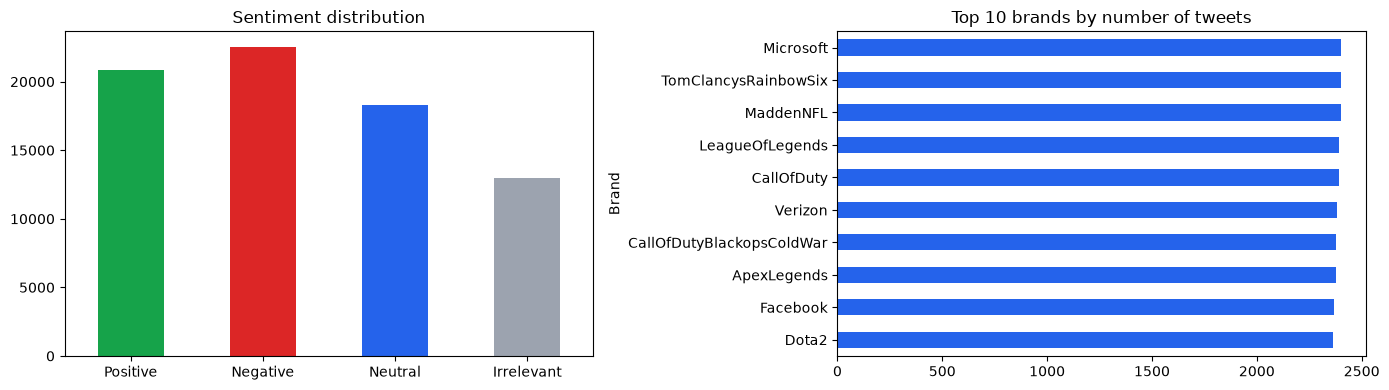

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df["Sentiment"].value_counts().reindex(LABELS).plot(
    kind="bar", ax=axes[0], color=["#16a34a", "#dc2626", "#2563eb", "#9ca3af"])
axes[0].set_title("Sentiment distribution")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

df["Brand"].value_counts().head(10).plot(kind="barh", ax=axes[1], color="#2563eb")
axes[1].set_title("Top 10 brands by number of tweets")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

In [4]:
df = df.dropna(subset=["Text"])
df = df[df["Sentiment"].isin(LABELS)].copy()
df["Clean"] = df["Text"].astype(str).map(clean_text)
df = df[df["Clean"].str.len() > 0]
df = df.drop_duplicates(subset="Clean").reset_index(drop=True)

print("Rows used for modelling:", len(df))
df["Sentiment"].value_counts()

Rows used for modelling: 60485


Sentiment
Negative      18534
Positive      16095
Neutral       15181
Irrelevant    10675
Name: count, dtype: int64

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df["Clean"], df["Sentiment"], test_size=0.2,
    stratify=df["Sentiment"], random_state=42)

vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
Xtr = vectorizer.fit_transform(X_train)
Xte = vectorizer.transform(X_test)
print("Train matrix:", Xtr.shape, "| Test matrix:", Xte.shape)

Train matrix: (48388, 5000) | Test matrix: (12097, 5000)


In [6]:
candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Linear SVC": LinearSVC(),
}

trained, comparison = {}, {}
for name, model in candidates.items():
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    comparison[name] = {
        "accuracy": float(accuracy_score(y_test, pred)),
        "macro_f1": float(f1_score(y_test, pred, average="macro")),
    }
    trained[name] = model

results = pd.DataFrame(comparison).T.round(4)
best_model_name = results["macro_f1"].idxmax()
best_model = trained[best_model_name]
print("Best model:", best_model_name)
results

Best model: Linear SVC


,accuracy,macro_f1
Logistic Regression,0.6942,0.6795
Multinomial Naive Bayes,0.6381,0.6118
Linear SVC,0.7195,0.7079


              precision    recall  f1-score   support

    Positive       0.70      0.75      0.72      3219
    Negative       0.75      0.80      0.78      3707
     Neutral       0.72      0.68      0.70      3036
  Irrelevant       0.68      0.59      0.63      2135

    accuracy                           0.72     12097
   macro avg       0.71      0.70      0.71     12097
weighted avg       0.72      0.72      0.72     12097



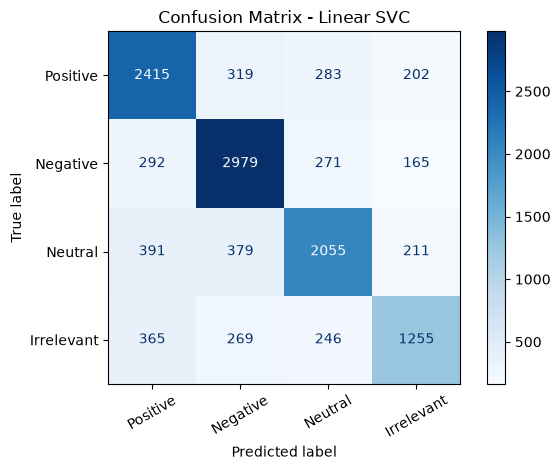

In [7]:
pred = best_model.predict(Xte)
print(classification_report(y_test, pred, labels=LABELS, zero_division=0))

cm = confusion_matrix(y_test, pred, labels=LABELS)
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap="Blues", xticks_rotation=30)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

In [8]:
os.makedirs("Models", exist_ok=True)

with open("Models/tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(vectorizer, f)
with open("Models/sentiment_svm_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

report = classification_report(y_test, pred, labels=LABELS, output_dict=True, zero_division=0)
metrics = {
    "best_model": best_model_name,
    "models": comparison,
    "labels": LABELS,
    "report": {k: v for k, v in report.items() if k in LABELS or k in ("macro avg", "weighted avg")},
    "confusion_matrix": cm.tolist(),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
}
with open("Models/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved to:", os.path.abspath("Models"))
print(os.listdir("Models"))

Saved to: d:\CITI[python]\Final Project\Twitter platform Sentiment Analysis\Models
['metrics.json', 'sentiment_svm_model.pkl', 'tfidf_vectorizer.pkl']


## Quick prediction test

In [9]:
def predict(text):
    X = vectorizer.transform([clean_text(text)])
    return best_model.predict(X)[0]


for t in ["I absolutely love this game!",
          "this patch is not good, I hate it",
          "Anyone know when the sale ends?"]:
    print(f"{predict(t):<11} <- {t}")

Positive    <- I absolutely love this game!
Negative    <- this patch is not good, I hate it
Neutral     <- Anyone know when the sale ends?
